# Backbone transfer: CNN-LSTM, TCN, Transformer on Panasonic to CMU eVTOL

This notebook runs `scripts/benchmarks/run_backbone_transfer_cmu.py`, which
reimplements the Vidal transfer protocol (Panasonic 25 C 1 Hz source, nested
chronological target-label budgets 0/1/5/10/40/100%, full-parameter fine-tuning
restarted from the frozen source checkpoint at every budget) for three generic
backbones already registered in `battery_benchmark.models`: `cnn_lstm`, `tcn`,
and `transformer_encoder`. It does not import or modify
`battery_benchmark.reproductions.vidal_2019`; the published Vidal LSTM CMU
results in `docs/benchmarks/vidal_panasonic_to_cmu_evtol_results_v0_1.md` are
unaffected.

Checkpointing is fine-grained: the source checkpoint for each (model, seed) is
saved to Drive as soon as it finishes, and every single (model, seed, cell,
budget) result is written to its own file the moment it finishes -- `cell_metrics.csv`
is rewritten after every one of those, not just once per cell. `--resume`
skips anything already on disk, so a Colab disconnect costs at most the one
budget that was in flight, not a whole cell or backbone.

CMU `soc_dynamic` is a development reference, not laboratory ground truth;
these runs are `formal_benchmark_eligible=false`.

In [29]:
from pathlib import Path
import os, subprocess, sys, tempfile
from urllib.parse import urlunsplit

from google.colab import drive, userdata
drive.mount('/content/drive')

REPO = Path('/content/battery-soc-transfer-benchmark')
REPO_URL = urlunsplit(('https', 'github.com', '/zhangcastle/battery-soc-transfer-benchmark.git', '', ''))
github_token = userdata.get('GITHUB_TOKEN')
if not github_token:
    raise RuntimeError('Add the GITHUB_TOKEN Colab Secret and enable Notebook access')
if REPO.exists() and not (REPO / '.git').exists():
    raise RuntimeError(f'Remove incomplete checkout and rerun: {REPO}')
with tempfile.TemporaryDirectory() as temp_dir:
    askpass = Path(temp_dir) / 'git-askpass.sh'
    askpass.write_text('#!/bin/sh\ncase "$1" in\n*Username*) echo "x-access-token" ;;\n*) printf "%s" "$GITHUB_TOKEN" ;;\nesac\n')
    askpass.chmod(0o700)
    git_env = os.environ.copy()
    git_env.update({'GIT_ASKPASS': str(askpass), 'GIT_TERMINAL_PROMPT': '0', 'GITHUB_TOKEN': github_token})
    command = (['git', '-C', str(REPO), 'pull', '--ff-only'] if (REPO / '.git').exists() else ['git', 'clone', '--depth', '1', REPO_URL, str(REPO)])
    result = subprocess.run(command, env=git_env, text=True, capture_output=True)
del github_token
if result.returncode:
    raise RuntimeError('Authenticated GitHub setup failed; check token permission')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(REPO)], check=True)
os.chdir(REPO)
src_path = str(REPO / 'src')
if src_path not in sys.path:
    sys.path.insert(0, src_path)
print('Repository ready:', subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repository ready: 087ab740b092668531c9b6d09ff6babfbab328ff


## Paths (Drive-persisted input/output roots)

Defined once, right after the clone, so every later cell -- including the
smoke test -- uses the real Drive-mounted Panasonic path instead of a
fallback that only exists for people who haven't set up
`configs/paths/colab_drive.yaml`.

In [30]:
import torch
from battery_benchmark.utils.config import load_yaml

PATHS = load_yaml(REPO / 'configs/paths/colab_drive.yaml')
PANASONIC_ROOT = Path(PATHS['raw_data_root']) / 'Panasonic_18650PF'
CMU_BASE_ROOT = REPO / 'outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel'
CMU_CONDITION_ROOT = REPO / 'outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel'
CMU_MANIFEST = REPO / 'data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv'
RESULT_ROOT = Path(PATHS['output_root']) / 'benchmarks/panasonic_to_cmu_evtol/backbone_transfer_ns_relabel_v1'

for path in (PANASONIC_ROOT, CMU_BASE_ROOT, CMU_CONDITION_ROOT, CMU_MANIFEST):
    assert path.exists(), f'Missing required input: {path}'

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
print('panasonic root:', PANASONIC_ROOT)
print('results (saved to Drive, survives a disconnect):', RESULT_ROOT)

device: cuda
panasonic root: /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF
results (saved to Drive, survives a disconnect): /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/backbone_transfer


## Protocol

- Source: Panasonic NCR18650PF, 25 C only, all nine profiles, 1 Hz, 50-step
  non-overlapping windows, train-only min-max normalisation (matches the
  Vidal Case 1 reconstruction assumptions documented in
  `docs/known_uncertainties.md`).
- Target budgets: `zero_shot`, `1pct`, `5pct`, `10pct`, `partial` (~40%), `full`
  (100%) -- the same nested mission-budget flags already frozen in
  `cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv` and used by the published
  Vidal LSTM sweep, so budget points line up exactly across backbones.
- Every budget restarts full-parameter fine-tuning from the same frozen
  source checkpoint (Vidal Case 2 pattern); no adapted state carries across
  budgets or cells.
- Model capacity is intentionally left at each backbone's default
  configuration rather than shrunk to match Vidal's 571-parameter LSTM;
  `n_parameters` is recorded per model in every result row and in
  `run_metadata.json` so capacity differences stay visible rather than being
  read as an architecture effect.

## Before the full sweep: a 2-minute smoke test

Run this once after a fresh clone/pull to catch a broken import or a bad
path before committing GPU time to the full sweep. It uses 2 epochs, one
cell, and two budgets, and writes to a throwaway output folder.

In [31]:
smoke_root = Path('/content/backbone_smoke_test')
subprocess.run(
    [
        sys.executable, '-u', str(REPO / 'scripts/benchmarks/run_backbone_transfer_cmu.py'),
        '--panasonic-data-root', str(PANASONIC_ROOT),
        '--cmu-base-root', str(CMU_BASE_ROOT),
        '--cmu-condition-root', str(CMU_CONDITION_ROOT),
        '--cmu-manifest', str(CMU_MANIFEST),
        '--output-root', str(smoke_root),
        '--models', 'cnn_lstm',
        '--cells', 'VAH01',
        '--budgets', 'zero_shot', '1pct',
        '--source-epochs', '2', '--transfer-epochs', '2',
        '--device', device,
    ],
    check=True,
)
print('smoke test passed')

smoke test passed


## Setup for the full sweep

`SEEDS = [42]` by default -- extend to `[42, 43, 44]` for a 3-seed run once
the single-seed sweep looks sane. Multi-seed multiplies the source
pretraining cost by the number of seeds, so it's worth checking the
single-seed curve first.

In [32]:
import pandas as pd
from IPython.display import display

CELLS = ['VAH01', 'VAH17', 'VAH27', 'VAH30', 'VAH15', 'VAH12', 'VAH11']
BUDGETS = ['zero_shot', '1pct', '5pct', '10pct', 'partial', 'full']
SEEDS = [42]
SOURCE_EPOCHS, TRANSFER_EPOCHS, BATCH_SIZE = 200, 100, 64

def run_backbone(model_name: str) -> None:
    command = [
        sys.executable, '-u', str(REPO / 'scripts/benchmarks/run_backbone_transfer_cmu.py'),
        '--panasonic-data-root', str(PANASONIC_ROOT),
        '--cmu-base-root', str(CMU_BASE_ROOT),
        '--cmu-condition-root', str(CMU_CONDITION_ROOT),
        '--cmu-manifest', str(CMU_MANIFEST),
        '--output-root', str(RESULT_ROOT),
        '--models', model_name,
        '--cells', *CELLS,
        '--budgets', *BUDGETS,
        '--seeds', *[str(s) for s in SEEDS],
        '--source-epochs', str(SOURCE_EPOCHS),
        '--transfer-epochs', str(TRANSFER_EPOCHS),
        '--batch-size', str(BATCH_SIZE),
        '--device', device,
        '--resume',
    ]
    subprocess.run(command, check=True)

## Run: cnn_lstm

Split into one cell per backbone so a disconnect during (say) `tcn` doesn't
require re-touching `cnn_lstm`'s already-finished cells -- with `--resume`
and the fine-grained checkpointing above, re-running a finished backbone's
cell is nearly instant (every budget is skipped).

In [35]:
run_backbone('cnn_lstm')

## Run: tcn

In [ ]:
run_backbone('tcn')

## Run: transformer_encoder

In [ ]:
run_backbone('transformer_encoder')

## Results -- read straight from Drive, one model at a time

Each model below reads only its own subfolder under `RESULT_ROOT`
(`RESULT_ROOT / '<model_name>'`) directly off Drive and plots on its own --
no shared aggregation step, and no dependency on `cell_metrics.csv` (an
older version of the run script overwrote that file per-model instead of
merging, so it may only reflect whichever backbone happened to run last).
Nothing here requires re-cloning or re-running the training script; it just
re-reads whatever per-(seed, cell, budget) JSON files are already sitting in
Drive right now (`<cell>/<budget>.json`, one flat result row per file -- this
is what the run script actually writes for fine-grained resume; a couple of
early cells also still have an old-format `<cell>/result.json` with a
`metrics` list inside from before that -- `load_model_results` below reads
either shape so nothing has to be manually cleaned up on Drive).

`budget_order` and `load_model_results` are shared helpers (no I/O, no
plotting) -- everything that actually touches Drive or draws a chart is
its own cell below.

In [37]:
import json as _json

budget_order = ['zero_shot', '1pct', '5pct', '10pct', 'partial', 'full']

def load_model_results(result_root: Path, model_name: str) -> pd.DataFrame:
    '''Read every seed/cell/budget result JSON for one model directly out of Drive.

    Handles both file shapes: the current one row per <budget>.json, and the
    old one metrics-list per <cell>/result.json.
    '''
    rows = []
    for result_path in sorted((result_root / model_name).glob('seed_*/*/*.json')):
        payload = _json.loads(result_path.read_text(encoding='utf-8'))
        if 'metrics' in payload:  # old shape: one file per cell, list of budget rows
            rows.extend(payload['metrics'])
        else:  # current shape: one file per (cell, budget), already a flat row
            rows.append(payload)
    df = pd.DataFrame(rows)
    if not df.empty:
        df = df.drop_duplicates(subset=['model', 'cell_id', 'budget', 'seed'], keep='last')
    return df

### cnn_lstm

Vidal LSTM reference (same six budget points, unweighted mean cell MAE):
35.56 / 8.29 / 6.72 / 5.77 / 5.67 / 2.49 for zero-shot / 1% / 5% / 10% /
Partial / Full.

cnn_lstm rows: 42


overall_mae_percent                                           \
budget                10pct    1pct    5pct   full partial zero_shot   
cell_id                                                                
VAH01                11.834  10.591  10.625  2.497   9.439     4.882   
VAH11                14.085  15.155  14.484  5.934  10.662     5.203   
VAH12                14.418  16.388  16.386  1.748   3.506     8.052   
VAH15                 5.149   6.098   4.886  1.489   4.218     4.993   
VAH17                 9.562  10.012   8.997  1.568   5.944     4.631   
VAH27                 8.309   9.314   8.458  2.783   7.077     3.995   
VAH30                 6.223   8.510   7.265  1.916   4.135     6.971   

        overall_rmse_percent                                           
budget                 10pct    1pct    5pct   full partial zero_shot  
cell_id                                                                
VAH01                 13.019  12.061  12.004  3.905  10.493     7.513  
VAH11                 17.470  18.305  17.706  6.965  12.029    10.293  
VAH12                 17.794  19.425  19.363  2.671   6.822    11.649  
VAH15                  6.936   7.583   6.747  1.829   5.452     6.069  
VAH17                 11.105  11.608  10.952  4.116   7.149     6.725  
VAH27                  9.783  10.597  10.077  4.548   8.030     5.237  
VAH30                  9.017  10.828   9.772  4.916   6.242    11.076

,overall_mae_percent
budget,
zero_shot,5.532
1pct,10.867
5pct,10.157
10pct,9.940
partial,6.426
full,2.562


<Axes: title={'center': 'cnn_lstm'}, xlabel='Target-label budget', ylabel='Mean MAE across 7 cells (%)'>

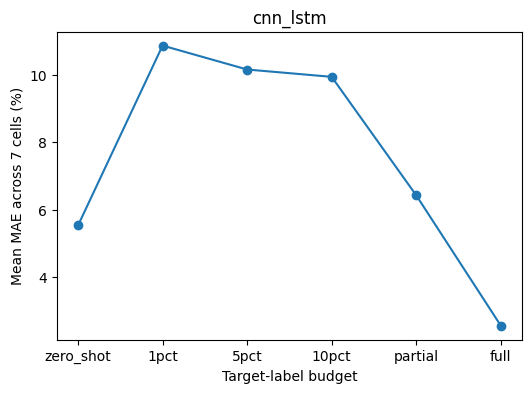

In [38]:
cnn_lstm_result = load_model_results(RESULT_ROOT, 'cnn_lstm')
print('cnn_lstm rows:', len(cnn_lstm_result))

cnn_lstm_pivot = cnn_lstm_result.pivot_table(
    index='cell_id', columns='budget',
    values=['overall_mae_percent', 'overall_rmse_percent'],
).round(3)
display(cnn_lstm_pivot)

cnn_lstm_curve = (
    cnn_lstm_result.groupby('budget')['overall_mae_percent']
    .mean().reindex(budget_order).round(3)
)
display(cnn_lstm_curve)
cnn_lstm_curve.plot(
    marker='o', figsize=(6, 4), title='cnn_lstm',
    ylabel='Mean MAE across 7 cells (%)', xlabel='Target-label budget',
)

### tcn

tcn rows: 42


overall_mae_percent                                           \
budget                10pct    1pct    5pct   full partial zero_shot   
cell_id                                                                
VAH01                 6.808   7.524   5.832  2.901   6.338     9.083   
VAH11                12.663  13.952  13.967  6.035   9.328     4.337   
VAH12                 9.059   7.623   6.927  2.026   4.026    10.480   
VAH15                 3.629   4.247   2.838  1.048   2.610     9.742   
VAH17                 7.128   6.074   6.515  1.875   6.239     9.335   
VAH27                 5.323   4.839   5.823  2.372   4.836     8.504   
VAH30                 4.287   6.464   5.841  1.766   3.778     9.019   

        overall_rmse_percent                                           
budget                 10pct    1pct    5pct   full partial zero_shot  
cell_id                                                                
VAH01                 11.108  10.782  10.731  5.067   9.386    11.125  
VAH11                 15.899  16.741  17.363  7.655  12.212     8.418  
VAH12                 11.569  11.716  10.399  3.988   7.177    13.804  
VAH15                  6.234   6.225   5.360  1.738   5.153    10.906  
VAH17                 10.915   9.804  10.463  3.983   8.265    10.996  
VAH27                  7.472   7.509   7.759  3.893   6.410     9.688  
VAH30                  8.711   9.406   9.108  4.181   7.650    12.355

,overall_mae_percent
budget,
zero_shot,8.643
1pct,7.246
5pct,6.820
10pct,6.985
partial,5.308
full,2.575


<Axes: title={'center': 'tcn'}, xlabel='Target-label budget', ylabel='Mean MAE across 7 cells (%)'>

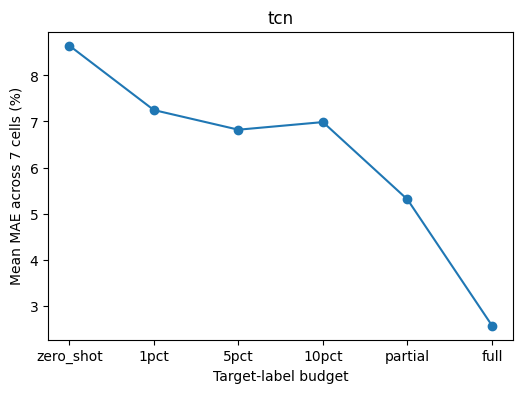

In [39]:
tcn_result = load_model_results(RESULT_ROOT, 'tcn')
print('tcn rows:', len(tcn_result))

tcn_pivot = tcn_result.pivot_table(
    index='cell_id', columns='budget',
    values=['overall_mae_percent', 'overall_rmse_percent'],
).round(3)
display(tcn_pivot)

tcn_curve = (
    tcn_result.groupby('budget')['overall_mae_percent']
    .mean().reindex(budget_order).round(3)
)
display(tcn_curve)
tcn_curve.plot(
    marker='o', figsize=(6, 4), title='tcn',
    ylabel='Mean MAE across 7 cells (%)', xlabel='Target-label budget',
)

### transformer_encoder

transformer_encoder rows: 42


overall_mae_percent                                          \
budget                10pct    1pct   5pct   full partial zero_shot   
cell_id                                                               
VAH01                 8.791   3.246  5.402  2.167   4.064     4.408   
VAH11                 9.110   9.801  7.898  4.598   9.102     4.643   
VAH12                 6.135  10.310  7.723  0.878   2.974     6.939   
VAH15                 2.604   1.883  1.863  0.759   1.518     6.236   
VAH17                 5.200   3.342  3.359  0.786   5.233     5.185   
VAH27                 3.564   3.486  3.466  1.770   3.921     5.036   
VAH30                 3.759   7.151  5.424  0.988   3.241     4.528   

        overall_rmse_percent                                           
budget                 10pct    1pct    5pct   full partial zero_shot  
cell_id                                                                
VAH01                 10.684   6.729   8.064  2.445   6.107     5.937  
VAH11                 12.444  12.867  11.791  5.412  12.013     8.678  
VAH12                 10.212  13.947  11.671  1.117   4.231     9.893  
VAH15                  4.558   3.842   3.986  0.883   2.862     6.528  
VAH17                  8.273   6.587   7.153  1.012   6.637     6.040  
VAH27                  6.022   5.542   5.801  2.069   5.455     5.445  
VAH30                  8.094   9.445   8.822  1.315   6.170     6.355

,overall_mae_percent
budget,
zero_shot,5.282
1pct,5.603
5pct,5.019
10pct,5.595
partial,4.293
full,1.707


<Axes: title={'center': 'transformer_encoder'}, xlabel='Target-label budget', ylabel='Mean MAE across 7 cells (%)'>

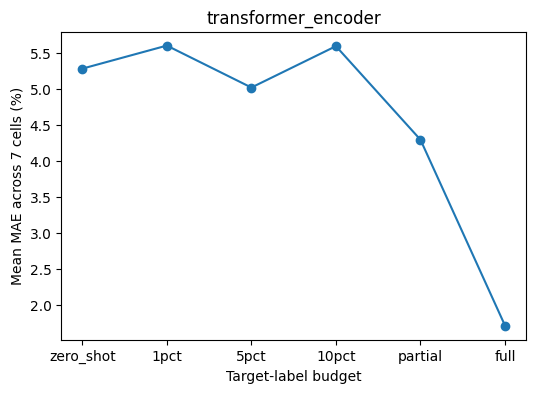

In [40]:
transformer_result = load_model_results(RESULT_ROOT, 'transformer_encoder')
print('transformer_encoder rows:', len(transformer_result))

transformer_pivot = transformer_result.pivot_table(
    index='cell_id', columns='budget',
    values=['overall_mae_percent', 'overall_rmse_percent'],
).round(3)
display(transformer_pivot)

transformer_curve = (
    transformer_result.groupby('budget')['overall_mae_percent']
    .mean().reindex(budget_order).round(3)
)
display(transformer_curve)
transformer_curve.plot(
    marker='o', figsize=(6, 4), title='transformer_encoder',
    ylabel='Mean MAE across 7 cells (%)', xlabel='Target-label budget',
)

### All three together (only run once each of the above has data)

Combines the three per-model tables already loaded above -- still no fresh
Drive scan, just lining up the three curves for a side-by-side comparison.

In [ ]:
combined = pd.concat([cnn_lstm_result, tcn_result, transformer_result], ignore_index=True)

combined_curve = (
    combined.groupby(['model', 'budget'])['overall_mae_percent']
    .mean()
    .unstack('model')
    .reindex(budget_order)
    .round(3)
)
display(combined_curve)
combined_curve.plot(marker='o', figsize=(7, 4), ylabel='Mean MAE across 7 cells (%)', xlabel='Target-label budget')